# 02 — TF-IDF + Logistic Regression baselines (Part C)

**Project 3 — Phase 1.** This notebook only *reads* the saved results of `src/step_c1_tfidf_baseline.py` (`artifacts/baselines/tfidf_metrics.json`); nothing is retrained here.

**Protocol**
- Input: `body` only, normalized by `src/preprocess.py` (same normalizer as the Transformer).
- TF-IDF vocabulary, IDF weights and class weights are fitted on the **train subset only** (`data/subset/train_supervised_sub.csv`, 536,243 rows; the same rows the Transformer is trained on).
- Features: word 1–2-grams + character 2–5-grams (`char_wb`), chosen because A6 showed heavy spelling noise (elongation, glued words).
- Model: Logistic Regression, `class_weight="balanced"`, one model per head. Each head uses only rows whose own target is valid.
- Evaluation: the **full** validation and **full** test sets, plus the extra subsets motivated by Part A: `long_text` (> 3 words), `text_not_in_train` (A5 duplicate-text leakage removed), and for rating_band `excluding_rate0` (A3: rate = 0 is suspicious).
- The test set is used for reporting only; no choice was made on it.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "artifacts").exists():
    ROOT = ROOT.parent
M = json.load(open(ROOT / "artifacts/baselines/tfidf_metrics.json", encoding="utf-8"))
SPLIT = json.load(open(ROOT / "artifacts/split/split_manifest.json", encoding="utf-8"))
REC = ["recommended", "no_idea", "not_recommended"]
BANDS = ["low", "medium", "high"]
print("ROOT:", ROOT)

ROOT: e:\digikala-review-transformer


## 1. Configuration

In [2]:
cfg = M["config"]
display(pd.DataFrame({"value": cfg}).astype(str))
print(f"Elapsed: {M.get('elapsed_seconds')} s")

,value
use_char_ngrams,True
C,2.0
max_iter,300
class_weight,balanced
word_ngrams,"[1, 2]"
char_ngrams,"[2, 5]"
n_features,310978
train_rows,536243
fit_on,data/subset/train_supervised_sub.csv


Elapsed: 1229.5 s


## 2. Split used for evaluation (from `split_manifest.json`)

In [3]:
rows = []
for name, s in SPLIT["splits"].items():
    rows.append({"split": name, "rows": s["rows"], "products": s["products"],
                 **{f"rec_{k}": v for k, v in s["recommendation"].items()},
                 **{f"band_{k}": v for k, v in s["rating_band"].items()}})
display(pd.DataFrame(rows).set_index("split"))
print("No product appears in two splits:", SPLIT["checks"]["no_product_in_two_splits"])

,rows,products,rec_recommended,rec_missing,rec_not_recommended,rec_no_idea,band_low,band_high,band_medium,band_invalid
split,,,,,,,,,,
train,4306382,232007,2913181,625203,353199,414799,765357,2802066,738958,1.0
validation,922671,49602,625390,133420,74927,88934,162487,600689,159495,NaN
test,922953,49976,621513,135233,76318,89889,163783,599261,159909,NaN


No product appears in two splits: True


## 3. Summary of metrics (validation and test)

In [4]:
rows = []
for split in ("validation", "test"):
    for head in ("recommendation", "rating_band"):
        for sub, m in M[split][head].items():
            rows.append({"split": split, "head": head, "subset": sub, "n": m["n"],
                         "macro_f1": m["macro_f1"], "balanced_acc": m["balanced_accuracy"],
                         "accuracy": m["accuracy"],
                         "ordinal_MAE": m.get("ordinal_mean_abs_error")})
summary = pd.DataFrame(rows)
display(summary.round(4))

,split,head,subset,n,macro_f1,balanced_acc,accuracy,ordinal_MAE
0,validation,recommendation,all,789251,0.6593,0.7049,0.8062,NaN
1,validation,recommendation,long_text,587099,0.6504,0.6964,0.7832,NaN
2,validation,recommendation,text_not_in_train,506772,0.6443,0.6889,0.7617,NaN
3,validation,rating_band,all,922671,0.5397,0.5546,0.6322,0.4873
4,validation,rating_band,excluding_rate0,843650,0.5613,0.6244,0.6659,0.4161
5,validation,rating_band,long_text,673883,0.5314,0.5510,0.6029,0.5261
6,validation,rating_band,text_not_in_train,584067,0.5293,0.5487,0.5907,0.5453
7,test,recommendation,all,787720,0.6601,0.7052,0.8043,NaN
8,test,recommendation,long_text,583463,0.6506,0.6962,0.7806,NaN
9,test,recommendation,text_not_in_train,503212,0.6440,0.6882,0.7584,NaN


## 4. Per-class precision / recall / F1 (test, all valid rows)

In [5]:
for head, names in (("recommendation", REC), ("rating_band", BANDS)):
    pc = M["test"][head]["all"]["per_class"]
    print(head)
    display(pd.DataFrame(pc).T.round(4))

recommendation


,precision,recall,f1,support
recommended,0.9532,0.8526,0.9001,621513.0
no_idea,0.3416,0.5325,0.4162,89889.0
not_recommended,0.6086,0.7306,0.6640,76318.0


rating_band


,precision,recall,f1,support
low,0.4571,0.4980,0.4767,163783.0
medium,0.3381,0.4561,0.3883,159909.0
high,0.8138,0.7181,0.7630,599261.0


## 5. Confusion matrices (test, all valid rows; rows = true, columns = predicted)

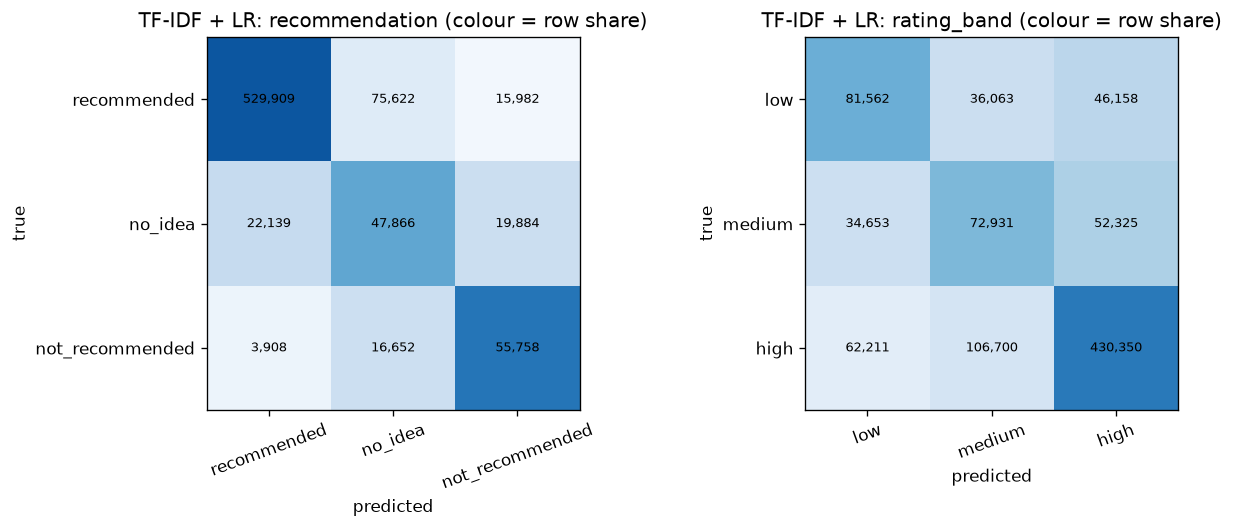

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=120)
for ax, (head, names) in zip(axes, (("recommendation", REC), ("rating_band", BANDS))):
    cm = np.array(M["test"][head]["all"]["confusion_matrix"])
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(3)); ax.set_xticklabels(names, rotation=20)
    ax.set_yticks(range(3)); ax.set_yticklabels(names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"TF-IDF + LR: {head} (colour = row share)")
plt.tight_layout(); plt.show()

## 6. Ordinal error of the rating-band head (test)

In [7]:
rows = []
for sub, m in M["test"]["rating_band"].items():
    rows.append({"subset": sub, "MAE (band steps)": m["ordinal_mean_abs_error"],
                 "share distance 1": m["share_distance_1"], "share distance 2": m["share_distance_2"]})
display(pd.DataFrame(rows).round(4))

,subset,MAE (band steps),share distance 1,share distance 2
0,all,0.4838,0.2489,0.1174
1,excluding_rate0,0.4136,0.2519,0.0808
2,long_text,0.5236,0.2687,0.1274
3,text_not_in_train,0.5434,0.2745,0.1344


## 7. Conclusions

1. **The baseline is a real baseline, not a strawman.** Test Macro-F1 is about **0.660** (recommendation) and **0.543** (rating_band). Because both targets are imbalanced (8.25:1 and 3.78:1, A3), Macro-F1 and balanced accuracy are the headline metrics, not accuracy.
2. **`no_idea` and `medium` are the weak classes.** They are subjective, in-between labels (A3: `no_idea` mostly sits at rate 3; A5: identical short texts carry conflicting labels), so a bag-of-words model cannot separate them well. The confusion matrices show most errors are between adjacent classes.
3. **rate = 0 is label noise, and it costs the band head.** Excluding rate = 0 rows raises band Macro-F1 from 0.543 to about 0.565 and removes almost all distance-2 errors (A3 showed 80% of rate = 0 reviews are `recommended`). Reporting both numbers is therefore necessary.
4. **Duplicate-text leakage is small in effect.** The `text_not_in_train` subset scores slightly lower than `all` (about 0.644 vs 0.660 for recommendation), so memorising repeated short texts helps a little, but the product-grouped split is not hiding a large leak.
5. **Long texts are not easier.** `long_text` is slightly worse than `all`, consistent with A4/A6: longer reviews contain mixed opinions and negation (`ولی`, `نیست`), which word counts handle poorly.
6. **Validation and test agree** (compare section 3), so there is no sign of over-fitting to the validation set; no tuning was done on test.

The fine-tuned Transformer is compared against these exact numbers in notebook 03.